# Stage 3: Explainability Methods (XAI)

Implements and visualizes two saliency methods for face verification:
- **Gradient Saliency** — differentiable; `|∂(cosine_sim)/∂(img_a)|` averaged over channels
- **xFace** — model-agnostic; mask each grid cell and measure similarity drop

A correct saliency map for a genuine pair should highlight the periocular region, nose bridge, and jawline.

In [1]:
!pip install timm -q

## ⚙️ CONFIG — edit only this cell

In [2]:
import torch

# -----------------------------------------------------------------
# Paths
IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

# -----------------------------------------------------------------
# Dataset
N_PAIRS     = 900
N_GENUINE_1 = 300
N_IMPOSTER  = 300
NUM_FEATURES = 512
THRESHOLD   = 0.30

# -----------------------------------------------------------------
# XAI parameters
XFACE_GRID_SIZE  = 14    # divide 112x112 into 14x14 grid (8x8 px cells)
GRAD_SMOOTH_SIGMA = 2.0  # Gaussian smoothing sigma for gradient saliency

# Pairs to visualize (mix of genuine and imposter)
VIZ_GENUINE_PAIRS  = [0, 50, 100, 600, 750]   # from genuine splits
VIZ_IMPOSTER_PAIRS = [300, 350, 450]           # from imposter split

# -----------------------------------------------------------------
# Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

Device : cuda
GPU    : Tesla T4


## Imports

In [3]:
import os
import numpy as np
import cv2
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

## Backbone (iResNet-100)

In [4]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

## Data & Model Utilities

In [5]:
def preprocess(img):
    img = ((img / 255.0) - 0.5) / 0.5
    return torch.tensor(np.transpose(img, (2, 0, 1)).astype('float32'))

def load_image_raw(pair_idx, which):
    path = os.path.join(IMAGES_DIR, f"{pair_idx * 2 + which}.jpg")
    img  = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Missing: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def load_pair(pair_idx):
    img_a = preprocess(load_image_raw(pair_idx, 0)).to(DEVICE)
    img_b = preprocess(load_image_raw(pair_idx, 1)).to(DEVICE)
    return img_a, img_b

def is_genuine(pair_idx):
    return pair_idx < N_GENUINE_1 or pair_idx >= N_GENUINE_1 + N_IMPOSTER

def tensor_to_uint8(t):
    img = t.detach().cpu().numpy().transpose(1, 2, 0)
    return np.clip((img * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)

def load_model():
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location=DEVICE)
    if 'state_dict' in state:
        state = state['state_dict']
    m.load_state_dict(state)
    return m.to(DEVICE).eval()

model = load_model()
print("Model ready.")

Model ready.


## XAI Method 1: Gradient Saliency

Compute `∂(cosine_similarity) / ∂(img_a)`, take absolute value, average over color channels, and smooth with a Gaussian. Fast (one forward + one backward pass per pair).

In [6]:
def gradient_saliency(img_a, img_b, smooth_sigma=GRAD_SMOOTH_SIGMA):
    """
    Returns a (H, W) numpy saliency map in [0, 1].
    img_a, img_b : (3, H, W) tensors on DEVICE.
    """
    model.eval()
    img_a_var = img_a.clone().unsqueeze(0).requires_grad_(True)

    e_a = model(img_a_var)
    e_b = model(img_b.unsqueeze(0).detach())
    sim = F.cosine_similarity(e_a, e_b, dim=1)
    sim.backward()

    sal = img_a_var.grad.squeeze(0).abs().mean(dim=0).cpu().numpy()  # (H, W)
    if smooth_sigma > 0:
        sal = gaussian_filter(sal, sigma=smooth_sigma)
    sal = (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)
    return sal

## XAI Method 2: xFace (Masking-Based)

Divide the image into a grid, occlude each cell, measure the similarity drop. Cells that cause a large drop are important. No gradients needed — model-agnostic.

In [7]:
def xface_saliency(img_a, img_b, grid_size=XFACE_GRID_SIZE, mask_value=0.0):
    """
    Returns a (H, W) numpy saliency map in [0, 1].
    grid_size : number of cells per side (grid_size x grid_size total cells).
    """
    model.eval()
    H, W = img_a.shape[1], img_a.shape[2]
    cell_h, cell_w = H // grid_size, W // grid_size

    with torch.no_grad():
        e_b      = model(img_b.unsqueeze(0))
        e_a_orig = model(img_a.unsqueeze(0))
        base_sim = F.cosine_similarity(e_a_orig, e_b, dim=1).item()

    importance = np.zeros((H, W), dtype=np.float32)

    for i in range(grid_size):
        for j in range(grid_size):
            masked = img_a.clone()
            r0, r1 = i * cell_h, min((i + 1) * cell_h, H)
            c0, c1 = j * cell_w, min((j + 1) * cell_w, W)
            masked[:, r0:r1, c0:c1] = mask_value
            with torch.no_grad():
                e_m = model(masked.unsqueeze(0))
                sim = F.cosine_similarity(e_m, e_b, dim=1).item()
            importance[r0:r1, c0:c1] = max(base_sim - sim, 0.0)  # keep only drops

    importance = (importance - importance.min()) / (importance.max() - importance.min() + 1e-8)
    return importance

## Visualization Helpers

In [8]:
def saliency_overlay(img_tensor, sal_map, alpha=0.5):
    """Return (raw, heatmap, overlay) as uint8 numpy arrays."""
    raw     = tensor_to_uint8(img_tensor)
    heatmap = cv2.applyColorMap((sal_map * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = np.clip(alpha * heatmap + (1 - alpha) * raw, 0, 255).astype(np.uint8)
    return raw, heatmap, overlay


def visualize_xai(pair_idx, method='gradient', save=False):
    """Show image A, image B, saliency heatmap, and overlay side by side."""
    img_a, img_b = load_pair(pair_idx)
    label = 'Genuine' if is_genuine(pair_idx) else 'Imposter'

    with torch.no_grad():
        sim = F.cosine_similarity(
            model(img_a.unsqueeze(0)), model(img_b.unsqueeze(0)), dim=1
        ).item()

    if method == 'gradient':
        sal  = gradient_saliency(img_a, img_b)
        name = 'Gradient Saliency'
    else:
        sal  = xface_saliency(img_a, img_b)
        name = 'xFace'

    raw_a, hm, overlay = saliency_overlay(img_a, sal)
    raw_b = tensor_to_uint8(img_b)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, img, title in zip(axes,
                               [raw_a, raw_b, hm, overlay],
                               ['Image A', 'Image B', f'{name}', 'Overlay']):
        ax.imshow(img); ax.set_title(title, fontsize=11); ax.axis('off')
    fig.suptitle(f"Pair {pair_idx} — {label} | sim={sim:.4f}", fontsize=13)
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(OUTPUT_DIR, f'xai_{method}_pair{pair_idx}.png'), dpi=120)
    plt.show()

## Visualize Genuine Pairs

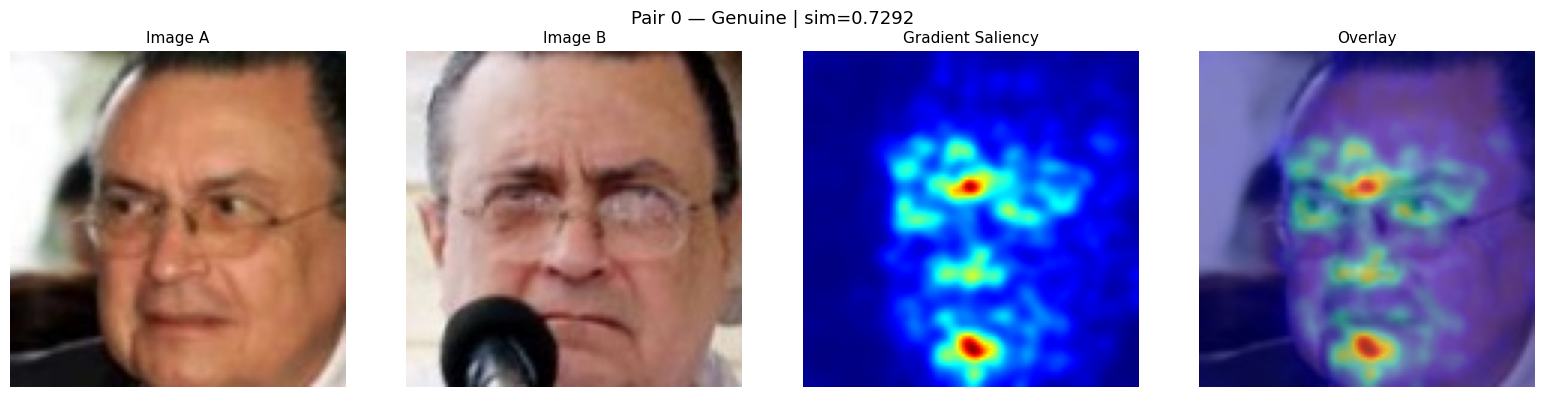

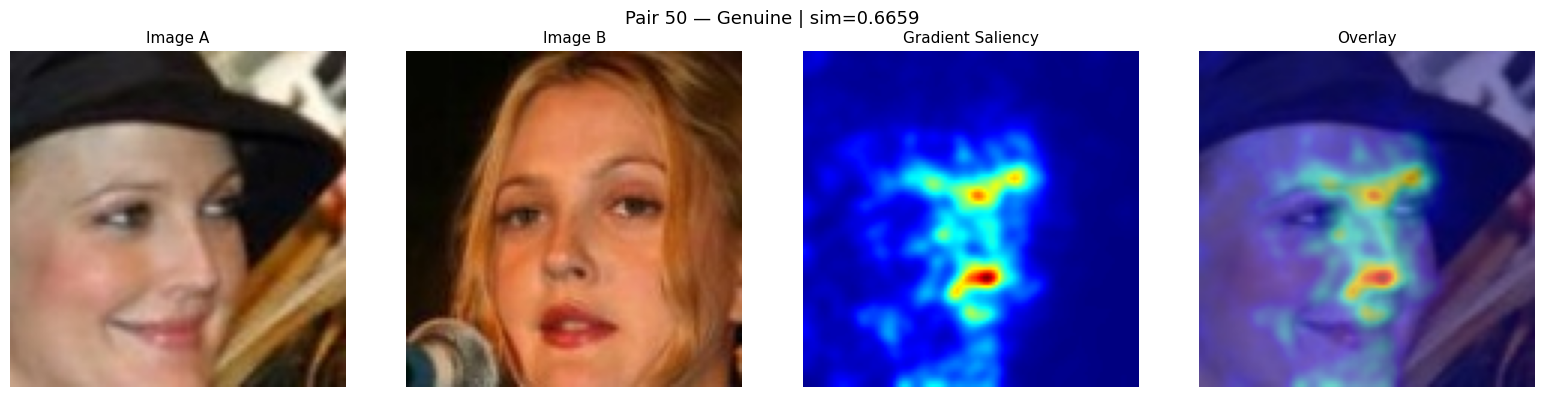

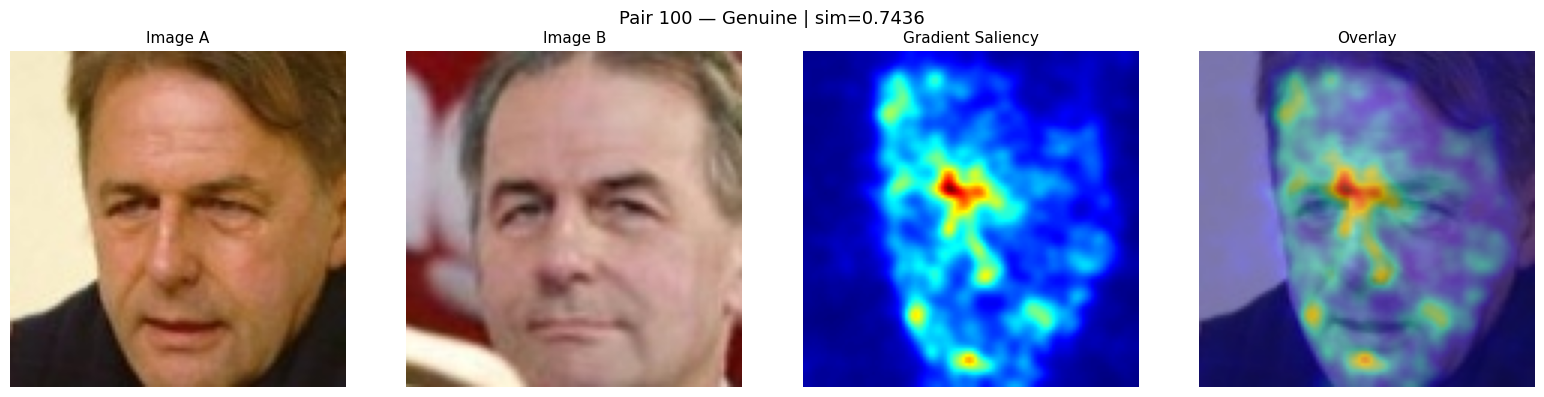

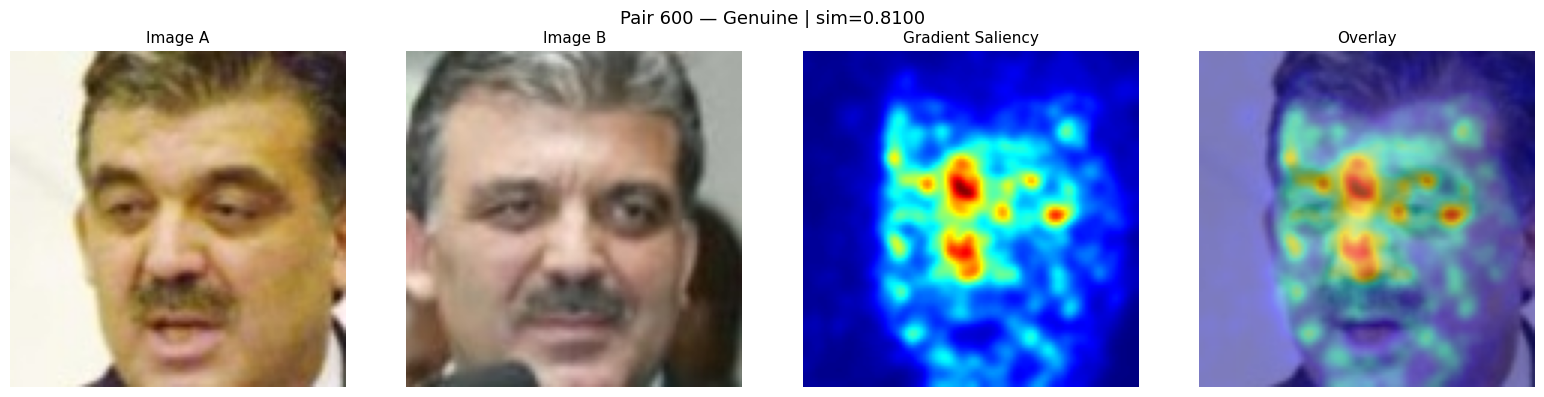

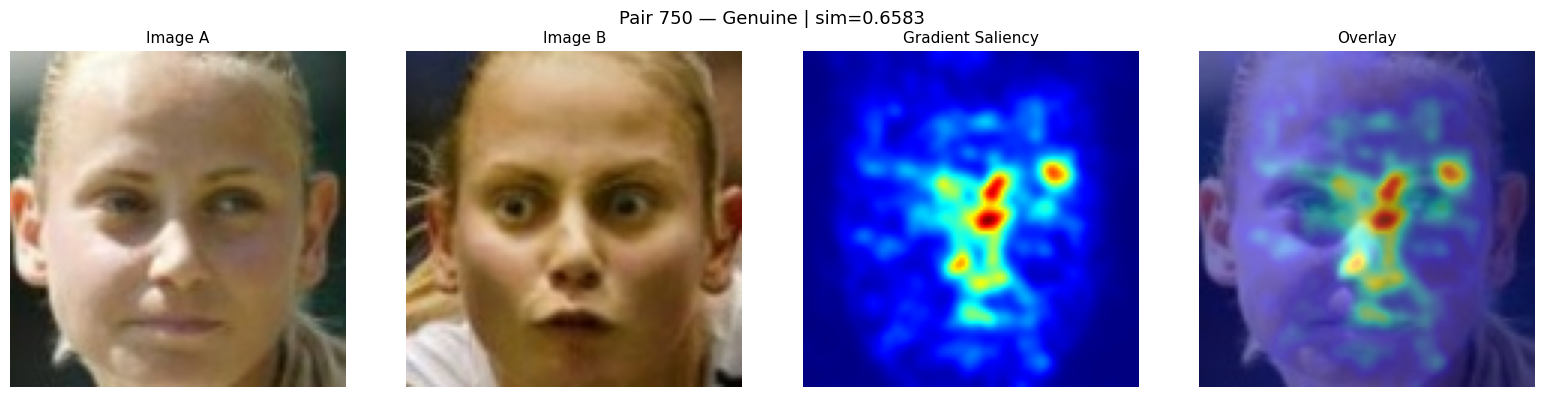

In [9]:
for idx in VIZ_GENUINE_PAIRS:
    visualize_xai(idx, method='gradient', save=True)

## Visualize Imposter Pairs

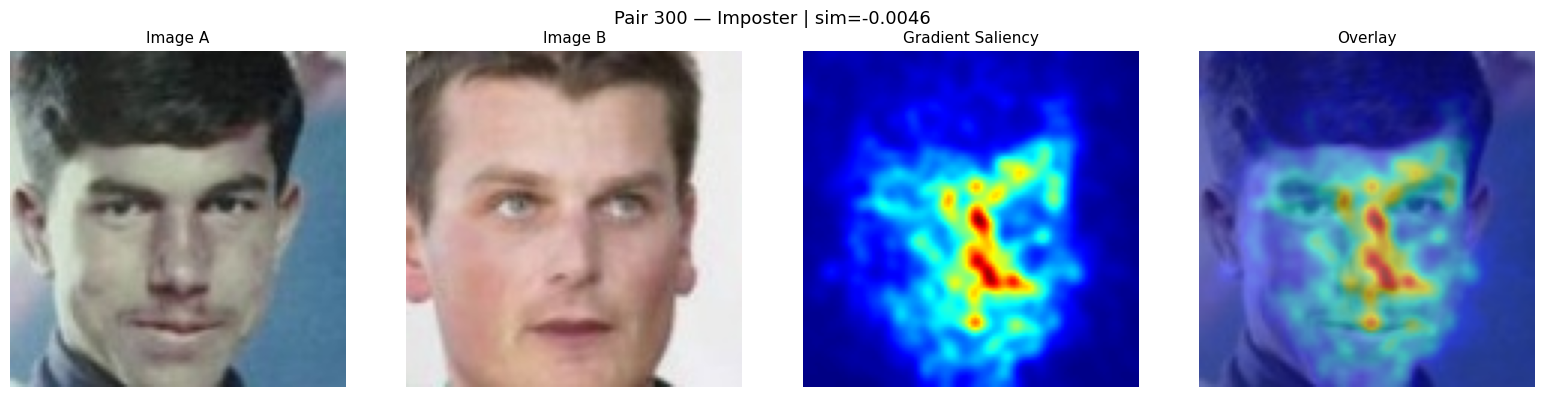

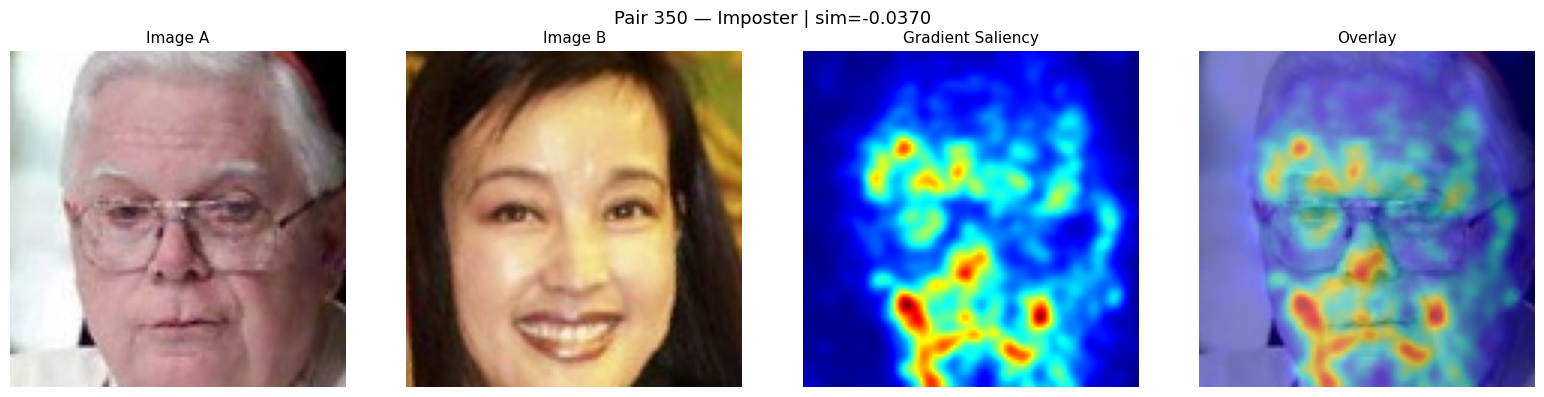

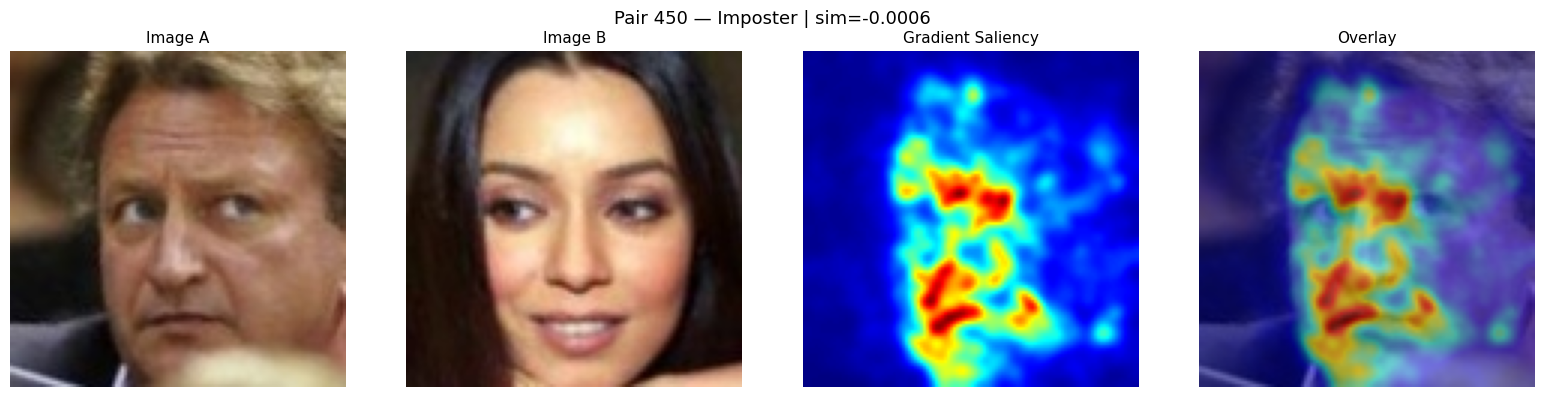

In [10]:
for idx in VIZ_IMPOSTER_PAIRS:
    visualize_xai(idx, method='gradient', save=True)

## Compare Both Methods on the Same Pair

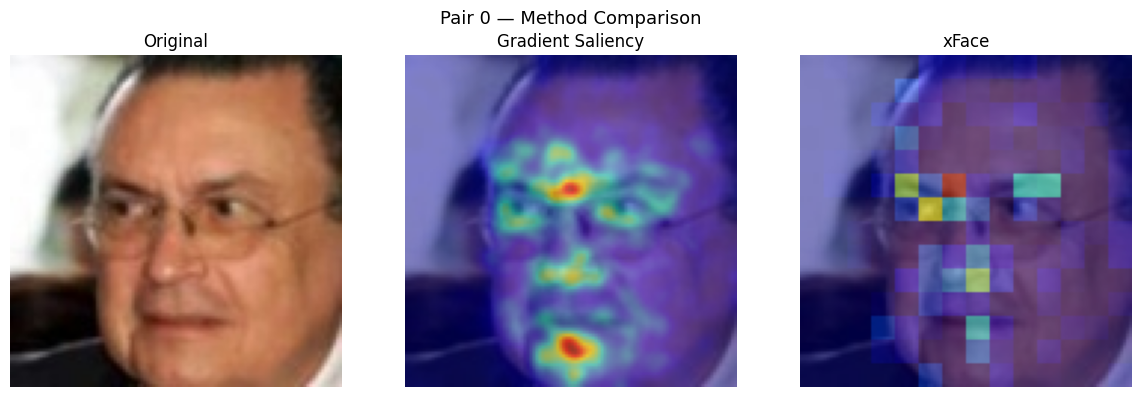

In [11]:
COMPARE_PAIR = VIZ_GENUINE_PAIRS[0]

img_a, img_b = load_pair(COMPARE_PAIR)
sal_grad   = gradient_saliency(img_a, img_b)
sal_xface  = xface_saliency(img_a, img_b)

raw_a                   = tensor_to_uint8(img_a)
_, _, overlay_grad      = saliency_overlay(img_a, sal_grad)
_, _, overlay_xface     = saliency_overlay(img_a, sal_xface)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes,
                           [raw_a, overlay_grad, overlay_xface],
                           ['Original', 'Gradient Saliency', 'xFace']):
    ax.imshow(img); ax.set_title(title, fontsize=12); ax.axis('off')
fig.suptitle(f"Pair {COMPARE_PAIR} — Method Comparison", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'xai_comparison_pair{COMPARE_PAIR}.png'), dpi=150)
plt.show()